# 02 — Fitting the psychometric functions

**Python port of `fit_all.m` (including the `fit_TIM_2P_mod` estimator).**

## What this notebook does

Notebook 01 produced, for every observer × condition × test position, a set of
points: *test luminance* → *proportion of "same" responses*. This notebook fits
a parametric curve to each of those sets and records the parameter estimates
and goodness of fit.

There are

$$21 \text{ observers} \times 4 \text{ conditions} \times 2 \text{ tasks} \times 3 \text{ orders} = 504 \text{ fits.}$$

"Orders" is 3 rather than 2 because, besides fitting the two test positions
separately, we also fit the two **aggregated** (counts summed level by level).
The aggregate fit is the "ignore the order effect" baseline.

The output is a table equivalent to `fit_all.csv`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import orderfx as O

PROJECT_ROOT = os.path.abspath('..')
REFERENCE_DIR = os.path.join(os.path.abspath('.'), 'reference')
OUTPUT_DIR = os.path.join(os.path.abspath('.'), 'outputs')
FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Tallies produced by notebook 01 (falling back to the MATLAB files if needed).
def _tally(name):
    p = os.path.join(OUTPUT_DIR, name)
    if not os.path.isfile(p):
        p = os.path.join(REFERENCE_DIR, name)
    return O.load_tally(p)

data = {1: _tally('seq_data.txt'),    # task 1 = sequential
        2: _tally('sim_data.txt')}    # task 2 = simultaneous

for t, df in data.items():
    print(O.TASK_LABELS[t - 1], df.shape)
data[1].head()

sequential (1176, 10)
simultaneous (1176, 10)


,sub_num,sub_code,cond,cond_label,standard,test_pos,test,total,same,diff
0,1,Cap,1,60_vs_60,26.4,1,17.6,24,3,21
1,1,Cap,1,60_vs_60,26.4,1,19.8,24,11,13
2,1,Cap,1,60_vs_60,26.4,1,22.4,24,17,7
3,1,Cap,1,60_vs_60,26.4,1,26.4,24,21,3
4,1,Cap,1,60_vs_60,26.4,1,30.3,24,17,7


## Step 1 — The model

A same/different judgement is not a simple "yes as the test gets brighter"
decision: the observer says **"same"** when the test is *close enough* to the
standard on either side. So the psychometric function is not monotone — it is a
peak centred near the standard.

The model used here (from Alcalá-Quintana & García-Pérez,
[doi:10.3389/fpsyg.2017.01142](https://doi.org/10.3389/fpsyg.2017.01142)) captures
that with a **difference of two Gaussian cumulatives** sharing a common slope:

$$\Psi_{\text{same}}(x) \;=\; \Phi\!\big(\beta\,(x-\alpha_1)\big) \;-\; \Phi\!\big(\beta\,(x-\alpha_2)\big)$$

where $x$ is the **log** test luminance and $\Phi$ is the standard normal CDF.

| parameter | meaning |
|---|---|
| $\alpha_1$ | lower edge of the range of test values judged "same" |
| $\alpha_2$ | upper edge of that range ($\alpha_2 \ge \alpha_1$) |
| $\beta$ | slope / **precision**: $1/\beta$ is the SD of the underlying Gaussians, so a large $\beta$ means sharp, decisive boundaries |

Two derived quantities carry the psychological interpretation:

* **Centre** $\alpha = (\alpha_1+\alpha_2)/2$ — the *point of subjective
  equality*: the test luminance that looks most like the standard. If the test
  in position 1 has to be physically brighter to look equal, its $\alpha$ is
  larger. This is the **Type A** (bias/shift) effect.
* **Width** $\alpha_2-\alpha_1$ together with $\beta$ — how tolerant and how
  precise the observer is. Differences in $\beta$ between positions are the
  **Type B** (precision) effect.

Why work in **log** luminance? Perceptual discriminability is roughly
proportional to stimulus magnitude (Weber's law), so on a log axis the function
has approximately the same shape regardless of the standard's level, which lets
the four conditions be compared on equal footing.

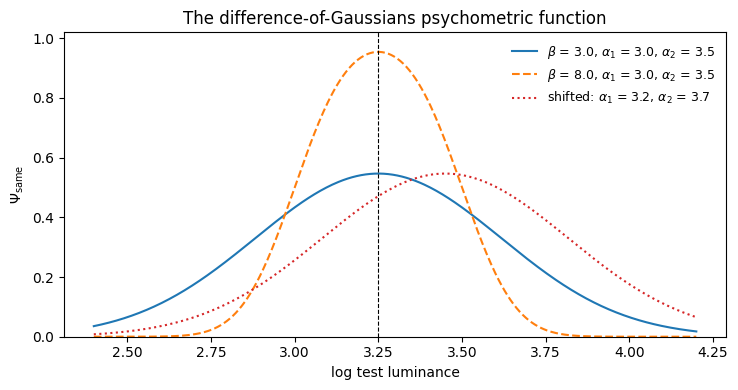

In [2]:
x = np.linspace(2.4, 4.2, 400)

fig, ax = plt.subplots(figsize=(7.5, 4))
for beta, ls in [(3.0, '-'), (8.0, '--')]:
    ax.plot(x, O.psi_same(x, beta, 3.0, 3.5), ls,
            label=rf'$\beta$ = {beta}, $\alpha_1$ = 3.0, $\alpha_2$ = 3.5')
ax.plot(x, O.psi_same(x, 3.0, 3.2, 3.7), ':', color='tab:red',
        label=r'shifted: $\alpha_1$ = 3.2, $\alpha_2$ = 3.7')
ax.axvline(3.25, color='k', lw=0.8, ls='--')
ax.set_xlabel('log test luminance'); ax.set_ylabel(r'$\Psi_{\rm same}$')
ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=9)
ax.set_title('The difference-of-Gaussians psychometric function')
fig.tight_layout(); plt.show()

Larger $\beta$ (dashed) gives a narrower, taller peak — a more precise
observer. Shifting both $\alpha$'s (dotted) slides the peak sideways without
changing its shape — a pure bias.

## Step 2 — How the parameters are estimated

### The likelihood

At test level $x_i$ the observer gave $s_i$ "same" and $d_i$ "different"
responses. Treating each trial as an independent Bernoulli draw, the
log-likelihood is

$$\ell(\beta,\alpha_1,\alpha_2) = \sum_i \Big[ s_i \log \Psi_{\text{same}}(x_i) + d_i \log\big(1-\Psi_{\text{same}}(x_i)\big) \Big]$$

and we minimise $-\ell$. Terms with a zero count contribute $0\log 0$, which is
treated as 0 (MATLAB's `nansum`; NumPy's `np.nansum` here).

### Reparameterisation

Instead of fitting $(\beta, \alpha_1, \alpha_2)$ directly, the code fits
$(\beta, \alpha_1, w)$ with $\alpha_2 = \alpha_1 + w$ and $w \ge 0$. This turns
the awkward ordering constraint $\alpha_1 \le \alpha_2$ into a simple bound on
one parameter.

### Bounds (copied from `fit_all.m`)

| parameter | bounds |
|---|---|
| $\beta$ | $[1,\,14]$ |
| $\alpha_1$ | $[0.25,\,4] \times \log(\text{standard})$ |
| $w$ | $[0,\,5]$ |

Three cells needed hand-tuned bounds in the MATLAB code (a very high-precision
observer whose $\beta$ hit the ceiling, and two cells where $\alpha_1$ needed to
drop far below the data range). Those exceptions are preserved verbatim in
`orderfx.SPECIAL_CASES`.

### Multiple starting points

The likelihood surface is not guaranteed to be unimodal, so the optimiser is
restarted from a grid of starting values and the best run wins. The original
FORTRAN code used a **3 × 3 × 3 = 27-point grid**; `fit_all.m`, being much
slower, used only 2 starts for $\beta$ and 1 each for the others, which
`00_readme.pdf` names as the reason for its few small discrepancies. Python is
fast enough for the full 27-point grid, so that is the default here
(`n_starts=3`).

**Where the 27 points go.** The FORTRAN rule is: to get $n$ starting values for
a parameter, lay down $n+2$ equally spaced points across its full range and
throw away the two end points, so that no search ever *starts* on a boundary:

$$\texttt{linspace(lb, ub, n+2)[1:-1]}$$

For $n = 3$ that is `linspace(lb, ub, 5)[2:4]` in MATLAB indexing. With the
default bounds this gives

| parameter | bounds | starting points |
|---|---|---|
| $\beta$ | $[1,\,14]$ | 4.25, 7.5, 10.75 |
| $\alpha_1$ | $[0.25,\,4]\times\log(\text{standard})$ | $1.1875,\;2.125,\;3.0625$ $\times \log(\text{standard})$ |
| $w$ | $[0,\,5]$ | 1.25, 2.5, 3.75 |

Because the starting points are derived from the bounds, the special cases need
only change the *bounds*: widening $\alpha_1$'s range to
$[0.05, 4]\times\log(\text{standard})$ automatically pulls its starting points
down, and raising $\beta$'s ceiling to 50 moves its starts to 14, 26 and 38.
This is why `orderfx.fit_cell` ignores the hand-tuned `alpha1_scale_start` of
`fit_all.m` when `n_starts=3` — that value only applies to the abbreviated
2-point MATLAB grid.

MATLAB uses `fmincon` with the SQP algorithm; SciPy's
`minimize(method='SLSQP')` is the direct equivalent for a smooth,
bound-constrained problem.

### Goodness of fit

The likelihood-ratio statistic

$$G^2 = 2\sum_{\text{cells}} O \log\frac{O}{E}$$

compares observed counts $O$ to counts $E$ expected under the fitted curve, and
is referred to a $\chi^2$ distribution. Degrees of freedom are

$$\text{df} = (\text{number of test levels with trials}) - 3 - (\text{number of cells with } E \le 0.06),$$

the last term dropping cells whose expected count is so small that the $\chi^2$
approximation would break down. **A large $p$-value means the model fits well**
— it is *not* a test of the order effect.

⚠️ Cells that end up with `df < 1` give no usable goodness-of-fit test and are
excluded from the group analyses in notebooks 03 and 04.

## Step 3 — Fit one cell, in detail

Before running all 504, let's follow a single fit end to end.

In [3]:
sub, cond, task, order = 1, 1, 1, 1     # Cap, condition 1, sequential, test 1st

cell = O.get_cell(data[task], sub, cond, order)
print('data going into the fit (log luminance):')
print(cell.to_string(index=False))

fit = O.fit_cell(cell, sub, cond, task, order, n_starts=3)
print()
print(f'beta    = {fit.Beta:8.4f}')
print(f'alpha_1 = {fit.Alpha_1:8.4f}   (= {np.exp(fit.Alpha_1):.2f} cd/m2)')
print(f'alpha_2 = {fit.Alpha_2:8.4f}   (= {np.exp(fit.Alpha_2):.2f} cd/m2)')
print(f'centre  = {(fit.Alpha_1 + fit.Alpha_2) / 2:8.4f}   '
      f'(= {np.exp((fit.Alpha_1 + fit.Alpha_2) / 2):.2f} cd/m2, the PSE)')
print(f'G2({fit.DegreesOfFreedom}) = {fit.LikelihoodRatioStatistic:.4f}, '
      f'p = {fit.LikelihoodRatioP_value:.4f}')
print(f'parameters on a boundary: {fit.BoundariesReached.strip() or "none"}')

data going into the fit (log luminance):
 log_test  log_standard  total  same  diff
 2.867899      3.273364     24     3    21
 2.985682      3.273364     24    11    13
 3.109061      3.273364     24    17     7
 3.273364      3.273364     24    21     3
 3.411148      3.273364     24    17     7
 3.546740      3.273364     24    10    14
 3.687879      3.273364     24     5    19



beta    =   5.9773
alpha_1 =   3.0211   (= 20.51 cd/m2)
alpha_2 =   3.5233   (= 33.90 cd/m2)
centre  =   3.2722   (= 26.37 cd/m2, the PSE)
G2(4) = 1.2822, p = 0.8644
parameters on a boundary: none


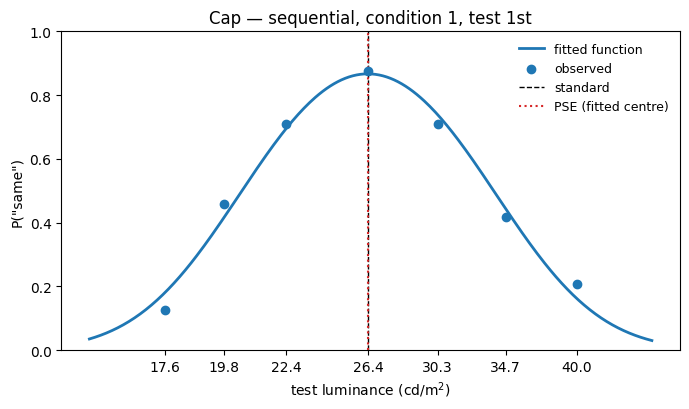

In [4]:
xs = np.linspace(cell.log_test.min() - 0.15, cell.log_test.max() + 0.15, 300)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(xs, O.psi_same(xs, fit.Beta, fit.Alpha_1, fit.Alpha_2), lw=2,
        color='tab:blue', label='fitted function')
ax.scatter(cell.log_test, cell['same'] / cell['total'], zorder=3,
           color='tab:blue', label='observed')
ax.axvline(cell.log_standard.iloc[0], color='k', ls='--', lw=1, label='standard')
ax.axvline((fit.Alpha_1 + fit.Alpha_2) / 2, color='tab:red', ls=':', lw=1.5,
           label='PSE (fitted centre)')
ax.set_xticks(cell.log_test)
ax.set_xticklabels([f'{v:.1f}' for v in np.exp(cell.log_test)])
ax.set_xlabel('test luminance (cd/m$^2$)'); ax.set_ylabel('P("same")')
ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=9)
ax.set_title(f'{O.NAMES[sub-1]} — {O.TASK_LABELS[task-1]}, condition {cond}, '
             f'test {O.ORDER_LABELS[task-1][order-1]}')
fig.tight_layout(); plt.show()

## Step 4 — Fit all 504 cells

For each of the three "orders":

* **order 1** — test first (sequential) / test on the left (simultaneous);
* **order 2** — test second / test on the right;
* **order 3** — *aggregated*: the trial counts of orders 1 and 2 added
  level-by-level before fitting, giving the position-blind baseline curve.

This takes roughly one to two minutes with the 27-point starting grid.

In [5]:
import warnings
from time import time

warnings.filterwarnings('ignore')          # SLSQP boundary-clipping chatter

N_STARTS = 3       # 3 -> 27-point grid (FORTRAN-like); 2 -> the fit_all.m grid

rows = []
t0 = time()
for sub in range(1, len(O.NAMES) + 1):
    for task in (1, 2):
        for cond in range(1, 5):
            for order in (1, 2, 3):
                cell = O.get_cell(data[task], sub, cond, order)
                if len(cell) == 0:
                    continue
                fit = O.fit_cell(cell, sub, cond, task, order, n_starts=N_STARTS)
                rows.append({
                    'Obs_number': sub,
                    'Obs_code': O.NAMES[sub - 1],
                    'Task': O.TASK_LABELS[task - 1],
                    'Condition': cond - 1,            # 0-based, as in fit_all.csv
                    'Standard': float(np.exp(cell.log_standard.iloc[0])),
                    'Test_order_location': O.ORDER_LABELS[task - 1][order - 1],
                    'Num_trials': int(cell['total'].sum()),
                    'Beta': fit.Beta,
                    'Alpha_1': fit.Alpha_1,
                    'Alpha_2': fit.Alpha_2,
                    'G2': fit.LikelihoodRatioStatistic,
                    'df': fit.DegreesOfFreedom,
                    'p_value': fit.LikelihoodRatioP_value,
                    'Boundaries': fit.BoundariesReached.strip(),
                    '_task': task, '_cond': cond, '_order': order,
                })
    print(f'subject {sub:2d} done  ({time() - t0:5.1f} s elapsed)')

fits = pd.DataFrame(rows)
print(f'\n{len(fits)} fits in {time() - t0:.1f} s')
fits.head(6)

subject  1 done  (  4.0 s elapsed)


subject  2 done  (  8.3 s elapsed)


subject  3 done  ( 11.9 s elapsed)


subject  4 done  ( 15.8 s elapsed)


subject  5 done  ( 19.6 s elapsed)


...

subject 18 done  ( 75.9 s elapsed)


subject 19 done  ( 80.4 s elapsed)


subject 20 done  ( 84.6 s elapsed)


subject 21 done  ( 88.2 s elapsed)

504 fits in 88.2 s


,Obs_number,Obs_code,Task,Condition,Standard,Test_order_location,Num_trials,Beta,Alpha_1,Alpha_2,G2,df,p_value,Boundaries,_task,_cond,_order
0,1,Cap,sequential,0,26.4,1st,168,5.977307,3.021124,3.523349,1.282242,4,0.864381,none,1,1,1
1,1,Cap,sequential,0,26.4,2nd,168,6.772719,2.982770,3.460177,6.845314,4,0.144292,none,1,1,2
2,1,Cap,sequential,0,26.4,agg,336,6.291307,2.999901,3.490038,5.325402,4,0.255508,none,1,1,3
3,1,Cap,sequential,1,13.2,1st,168,6.309668,2.242259,2.914894,3.792735,4,0.434782,none,1,2,1
4,1,Cap,sequential,1,13.2,2nd,168,8.920849,2.311984,2.852476,1.683878,4,0.793644,none,1,2,2
5,1,Cap,sequential,1,13.2,agg,336,7.424686,2.279905,2.881472,1.074869,4,0.898239,none,1,2,3


### Are the fits any good?

Under a correct model the $p$-values should be roughly uniform on $[0,1]$ and
only about 5% should fall below 0.05.

fits with df >= 1 : 503 of 504
p < 0.05          : 62 (12.3%)

fits with a parameter on a bound: 2
Boundaries
lower_Alpha_1    2


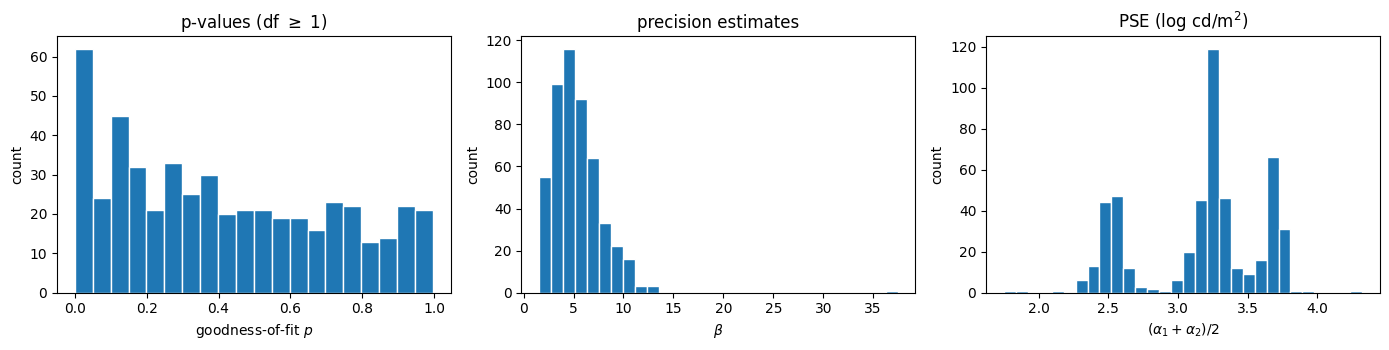

In [6]:
usable = fits[fits['df'] >= 1]
print(f'fits with df >= 1 : {len(usable)} of {len(fits)}')
print(f'p < 0.05          : {(usable.p_value < 0.05).sum()} '
      f'({100 * (usable.p_value < 0.05).mean():.1f}%)')
print()
hit = fits[fits.Boundaries != 'none']
print(f'fits with a parameter on a bound: {len(hit)}')
if len(hit):
    print(hit.Boundaries.value_counts().to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(usable.p_value, bins=20, color='tab:blue', edgecolor='w')
axes[0].set_xlabel('goodness-of-fit $p$'); axes[0].set_title('p-values (df $\\geq$ 1)')
axes[1].hist(fits.Beta, bins=30, color='tab:blue', edgecolor='w')
axes[1].set_xlabel(r'$\beta$'); axes[1].set_title('precision estimates')
axes[2].hist((fits.Alpha_1 + fits.Alpha_2) / 2, bins=30, color='tab:blue', edgecolor='w')
axes[2].set_xlabel(r'$(\alpha_1+\alpha_2)/2$'); axes[2].set_title('PSE (log cd/m$^2$)')
for a in axes:
    a.set_ylabel('count')
fig.tight_layout(); plt.show()

## Step 5 — Save the results

`fit_all_python.csv` has the same columns as the original `fit_all.csv`, plus a
`Boundaries` column flagging any parameter that finished on a bound.

In [7]:
cols = ['Obs_number', 'Obs_code', 'Task', 'Condition', 'Standard',
        'Test_order_location', 'Num_trials', 'Beta', 'Alpha_1', 'Alpha_2',
        'G2', 'df', 'p_value', 'Boundaries']
fit_path = os.path.join(OUTPUT_DIR, 'fit_all_python.csv')
fits[cols].to_csv(fit_path, index=False, float_format='%.5f')
print('wrote', fit_path)

wrote /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/fit_all_python.csv


## Step 6 — Per-subject panel figures

The MATLAB script drew, for each subject, a 4 × 6 grid of panels: four rows
(conditions) × six columns (sequential 1st / 2nd / aggregated, then
simultaneous left / right / aggregated). The same layout is reproduced here and
saved as a multi-page PDF, the analogue of `fit_all_1.pdf`.

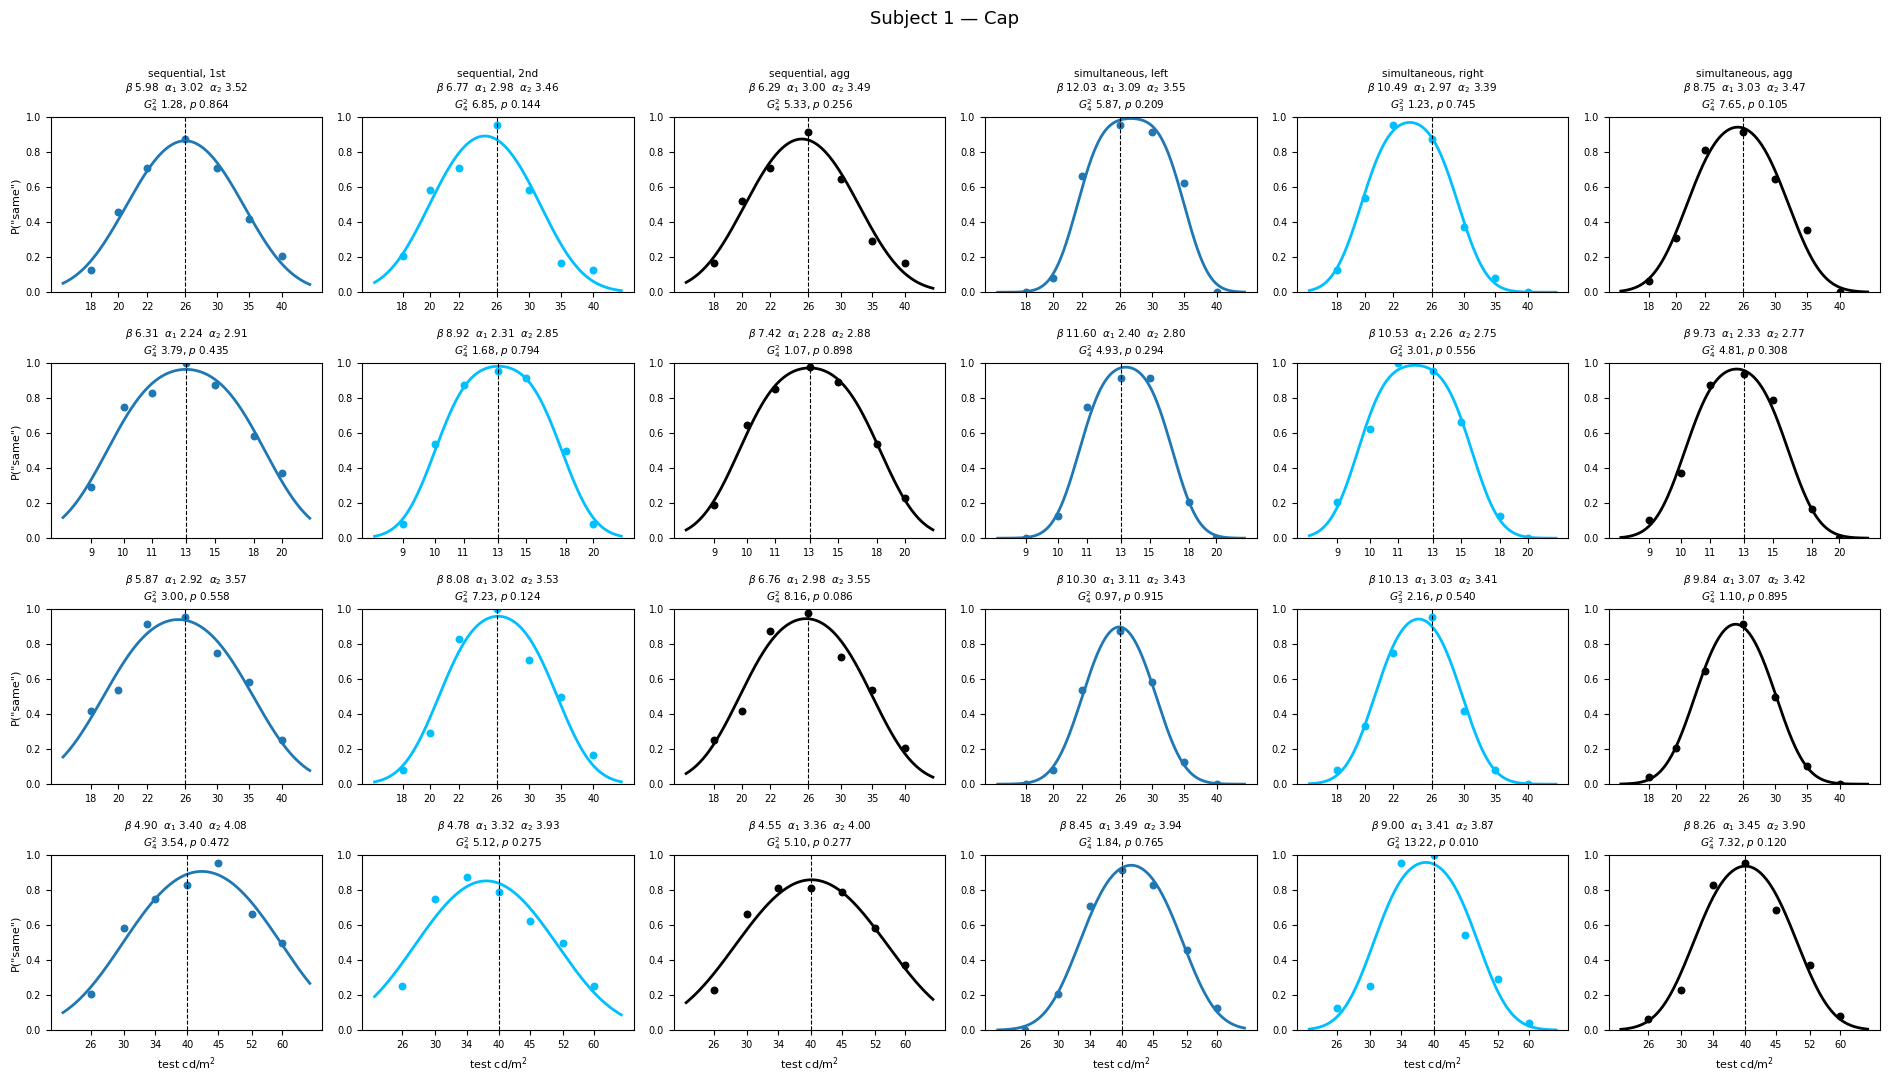

In [8]:
COLOURS = ['tab:blue', 'deepskyblue', 'black']

def plot_subject(sub, fits, data):
    fig, axes = plt.subplots(4, 6, figsize=(19, 11))
    for cond in range(1, 5):
        col = 0
        for task in (1, 2):
            for order in (1, 2, 3):
                ax = axes[cond - 1, col]; col += 1
                cell = O.get_cell(data[task], sub, cond, order)
                r = fits[(fits.Obs_number == sub) & (fits._task == task)
                         & (fits._cond == cond) & (fits._order == order)]
                if len(cell) == 0 or len(r) == 0:
                    ax.axis('off')
                    continue
                r = r.iloc[0]
                xs = np.linspace(cell.log_test.min() - 0.12,
                                 cell.log_test.max() + 0.12, 300)
                c = COLOURS[order - 1]
                ax.plot(xs, O.psi_same(xs, r.Beta, r.Alpha_1, r.Alpha_2), lw=2, color=c)
                ax.scatter(cell.log_test, cell['same'] / cell['total'], s=22, color=c)
                ax.axvline(cell.log_standard.iloc[0], color='k', ls='--', lw=0.8)
                ax.set_ylim(0, 1)
                ax.set_xticks(cell.log_test)
                ax.set_xticklabels([f'{v:.0f}' for v in np.exp(cell.log_test)], fontsize=6)
                ax.tick_params(labelsize=7)
                head = (f'{O.TASK_LABELS[task-1]}, {O.ORDER_LABELS[task-1][order-1]}\n'
                        if cond == 1 else '')
                ax.set_title(head +
                             rf'$\beta$ {r.Beta:.2f}  $\alpha_1$ {r.Alpha_1:.2f}  '
                             rf'$\alpha_2$ {r.Alpha_2:.2f}' + '\n' +
                             rf'$G^2_{{{int(r.df)}}}$ {r.G2:.2f}, $p$ {r.p_value:.3f}',
                             fontsize=7.5)
                if col == 1:
                    ax.set_ylabel('P("same")', fontsize=8)
                if cond == 4:
                    ax.set_xlabel('test cd/m$^2$', fontsize=8)
    fig.suptitle(f'Subject {sub} — {O.NAMES[sub-1]}', fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig

fig = plot_subject(1, fits, data)
plt.show()

In [9]:
from matplotlib.backends.backend_pdf import PdfPages

pdf_path = os.path.join(FIG_DIR, 'fit_all_python.pdf')
with PdfPages(pdf_path) as pdf:
    for sub in range(1, len(O.NAMES) + 1):
        fig = plot_subject(sub, fits, data)
        pdf.savefig(fig)
        plt.close(fig)
print('wrote', pdf_path)

wrote /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/figures/fit_all_python.pdf


## Step 7 — Verification against the FORTRAN results

`fit_all.csv` in the `reference` folder holds the estimates from the
authors' original FORTRAN program. Comparing against it is the strongest check
available on this port.

In [10]:
ref_path = os.path.join(REFERENCE_DIR, 'fit_all.csv')
if os.path.isfile(ref_path):
    ref = pd.read_csv(ref_path, skipinitialspace=True)
    ref.columns = [c.strip() for c in ref.columns]
    for c in ['Obs_code', 'Task', 'Test_order_location']:
        ref[c] = ref[c].str.strip()

    key = ['Obs_number', 'Task', 'Condition', 'Test_order_location']
    cmp = fits.merge(ref, on=key, suffixes=('_py', '_ref'))
    print(f'{len(cmp)} of {len(fits)} fits matched to the FORTRAN table\n')

    summary = []
    for c in ['Beta', 'Alpha_1', 'Alpha_2', 'G2', 'df']:
        d = (cmp[c + '_py'] - cmp[c + '_ref']).abs()
        summary.append({'parameter': c,
                        'max |diff|': d.max(),
                        'median |diff|': d.median(),
                        'n with |diff| > 0.01': int((d > 0.01).sum()),
                        'correlation': np.corrcoef(cmp[c + '_py'], cmp[c + '_ref'])[0, 1]})
    display(pd.DataFrame(summary).set_index('parameter').round(6))

    cmp['dA1'] = (cmp.Alpha_1_py - cmp.Alpha_1_ref).abs()
    worst = cmp.nlargest(5, 'dA1')[['Obs_number', 'Task', 'Condition',
                                    'Test_order_location', 'Alpha_1_py', 'Alpha_1_ref',
                                    'Alpha_2_py', 'Alpha_2_ref', 'Beta_py', 'Beta_ref',
                                    'G2_py', 'G2_ref', 'df_py']]
    print('\nlargest discrepancies in alpha_1:')
    display(worst.round(4))
else:
    print('fit_all.csv not found — skipping verification')

504 of 504 fits matched to the FORTRAN table



,max |diff|,median |diff|,n with |diff| > 0.01,correlation
parameter,,,,
Beta,1.941528,0.000003,2,0.999632
Alpha_1,1.121629,0.000003,3,0.994854
Alpha_2,0.001820,0.000003,0,1.000000
G2,0.003159,0.000005,0,1.000000
df,0.000000,0.000000,0,1.000000



largest discrepancies in alpha_1:


,Obs_number,Task,Condition,Test_order_location,Alpha_1_py,Alpha_1_ref,Alpha_2_py,Alpha_2_ref,Beta_py,Beta_ref,G2_py,G2_ref,df_py
488,21,sequential,2,agg,0.8183,1.9400,3.4678,3.4684,2.6016,2.6362,5.7886,5.7918,4
49,3,sequential,0,2nd,0.1637,0.3173,3.3376,3.3376,2.3852,2.3852,7.1346,7.1346,4
486,21,sequential,2,1st,0.1637,0.2776,3.5657,3.5657,1.5948,1.5950,4.3927,4.3929,4
310,13,simultaneous,3,right,3.6848,3.6844,3.7742,3.7760,37.4418,39.3833,0.0000,0.0000,-1
48,3,sequential,0,1st,2.5979,2.5979,3.3676,3.3676,2.6571,2.6571,0.9566,0.9566,4


### Reading the comparison

Expect $\alpha_2$, $G^2$ and df to agree to several decimals, and $\beta$ and
$\alpha_1$ to agree for almost every cell.

The handful of cells where $\alpha_1$ differs noticeably are all cases where the
data never drop back to zero on the low side — the observer said "different" at
every test level below the standard, so $\alpha_1$ sits well outside the tested
range and the likelihood is essentially **flat** in it. Two very different
$\alpha_1$ values then give the same fit, which is why $\alpha_2$, $G^2$ and df
still match exactly. It is an identifiability limitation of the data, not a
disagreement between the two implementations. Note that the same cells are the
ones `fit_all.m` had to give hand-tuned bounds.

One further cell (subject 13, simultaneous, condition 4, test right) is an
observer so precise that the fit is essentially perfect, `df` comes out
negative, and $\beta$ runs off to a large value. It is excluded from the group
analyses.

---

## Summary

* One difference-of-Gaussians psychometric function fitted per
  subject × condition × task × test position, plus an aggregated fit.
* Maximum likelihood via SLSQP with a 27-point starting grid and the same bounds
  and special cases as `fit_all.m`.
* $G^2$ goodness of fit with the same degrees-of-freedom rule.
* Results saved to `outputs/fit_all_python.csv` and per-subject panels to
  `outputs/figures/fit_all_python.pdf`.

**Next:** `03_equality_tests.ipynb` tests the same data without assuming a
model, and `04_manuscript_figures.ipynb` turns these parameters into the Type A
and Type B analyses and the figures that appear in the paper.